In [45]:
import sys

sys.path.append("../")

from src.data_preprocessing import (
    load_processed_aqi
)

from src.feature_engineering import (
    create_ml_features
)

from src.forecasting import (
    evaluate_forecast,
    create_fourier_features
)

print("All source modules imported successfully.")

All source modules imported successfully.


In [1]:
import sys
import os
import importlib.util

print("CURRENT DIRECTORY:")
print(os.getcwd())

print("\nPYTHON:")
print(sys.executable)

print("\nFIRST 15 PYTHON PATHS:")
for p in sys.path[:15]:
    print(p)

print("\nTENSORFLOW SPEC:")
spec = importlib.util.find_spec("tensorflow")
print("origin:", spec.origin)
print("locations:", spec.submodule_search_locations)

CURRENT DIRECTORY:
/Users/gyanvi/PycharmProjects/AQI-Time-Series-Forecasting/notebooks

PYTHON:
/Users/gyanvi/PycharmProjects/AQI-Time-Series-Forecasting/.venv-tf/bin/python

FIRST 15 PYTHON PATHS:
/Applications/PyCharm.app/Contents/plugins/python-ce/helpers/jupyter_debug
/Applications/PyCharm.app/Contents/plugins/python-ce/helpers/pydev
/Users/gyanvi/PycharmProjects/AQI-Time-Series-Forecasting
/Users/gyanvi/PycharmProjects/AQI-Time-Series-Forecasting/.venv-tf/lib/python3.12/site-packages/tensorflow/compiler/mlir
/opt/homebrew/Cellar/python@3.12/3.12.14/Frameworks/Python.framework/Versions/3.12/lib/python312.zip
/opt/homebrew/Cellar/python@3.12/3.12.14/Frameworks/Python.framework/Versions/3.12/lib/python3.12
/opt/homebrew/Cellar/python@3.12/3.12.14/Frameworks/Python.framework/Versions/3.12/lib/python3.12/lib-dynload

/Users/gyanvi/PycharmProjects/AQI-Time-Series-Forecasting/.venv-tf/lib/python3.12/site-packages

TENSORFLOW SPEC:
origin: /Users/gyanvi/PycharmProjects/AQI-Time-Series-For

In [3]:
import tensorflow as tf

print("TensorFlow version:", tf.__version__)
print("TensorFlow location:", tf.__file__)

TensorFlow version: 2.21.0
TensorFlow location: /Users/gyanvi/PycharmProjects/AQI-Time-Series-Forecasting/.venv-tf/lib/python3.12/site-packages/tensorflow/__init__.py


In [4]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

print("TensorFlow/Keras imported successfully!")

TensorFlow/Keras imported successfully!


In [5]:
# ============================================
# 2. LOAD CLEANED AQI DATA
# ============================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

aqi = pd.read_csv(
    "../data/processed/delhi_aqi_timeseries.csv"
)

aqi["Date"] = pd.to_datetime(aqi["Date"])

aqi = (
    aqi
    .sort_values("Date")
    .set_index("Date")
)

print("Shape:", aqi.shape)
print("Start:", aqi.index.min())
print("End:", aqi.index.max())
print("Missing AQI:", aqi["AQI"].isna().sum())

aqi.head()

Shape: (2009, 1)
Start: 2015-01-01 00:00:00
End: 2020-07-01 00:00:00
Missing AQI: 0


,AQI
Date,
2015-01-01,472.0
2015-01-02,454.0
2015-01-03,143.0
2015-01-04,319.0
2015-01-05,325.0


In [6]:
# ============================================
# 3. CHRONOLOGICAL SPLIT
# ============================================

train = aqi.loc[
    "2015-01-01":"2018-07-02"
].copy()

validation = aqi.loc[
    "2018-07-03":"2019-07-02"
].copy()

test = aqi.loc[
    "2019-07-03":"2020-07-01"
].copy()

print("Training:")
print(train.index.min(), "to", train.index.max())
print("Size:", len(train))

print("\nValidation:")
print(validation.index.min(), "to", validation.index.max())
print("Size:", len(validation))

print("\nFinal Test:")
print(test.index.min(), "to", test.index.max())
print("Size:", len(test))

Training:
2015-01-01 00:00:00 to 2018-07-02 00:00:00
Size: 1279

Validation:
2018-07-03 00:00:00 to 2019-07-02 00:00:00
Size: 365

Final Test:
2019-07-03 00:00:00 to 2020-07-01 00:00:00
Size: 365


In [7]:
# ============================================
# 4. SCALE AQI
# ============================================

from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler()

train_scaled = scaler.fit_transform(
    train[["AQI"]]
)

validation_scaled = scaler.transform(
    validation[["AQI"]]
)

test_scaled = scaler.transform(
    test[["AQI"]]
)

print("Train scaled range:",
      train_scaled.min(),
      train_scaled.max())

print("Validation scaled range:",
      validation_scaled.min(),
      validation_scaled.max())

print("Test scaled range:",
      test_scaled.min(),
      test_scaled.max())

Train scaled range: 0.0 1.0
Validation scaled range: 0.04949053857350801 0.7976710334788938
Test scaled range: 0.03202328966521107 0.9170305676855897


In [8]:
# ============================================
# 5. CREATE LSTM SEQUENCES
# ============================================

LOOKBACK = 30

def create_sequences(data, lookback):

    X = []
    y = []

    for i in range(lookback, len(data)):

        X.append(
            data[i-lookback:i, 0]
        )

        y.append(
            data[i, 0]
        )

    X = np.array(X)
    y = np.array(y)

    X = X.reshape(
        X.shape[0],
        X.shape[1],
        1
    )

    return X, y

In [9]:
# ============================================
# 6. TRAINING SEQUENCES
# ============================================

X_train, y_train = create_sequences(
    train_scaled,
    LOOKBACK
)

print("X_train:", X_train.shape)
print("y_train:", y_train.shape)

X_train: (1249, 30, 1)
y_train: (1249,)


In [10]:
# ============================================
# 7. VALIDATION SEQUENCES
# ============================================

validation_input = np.concatenate([
    train_scaled[-LOOKBACK:],
    validation_scaled
])

X_validation, y_validation = create_sequences(
    validation_input,
    LOOKBACK
)

print("X_validation:", X_validation.shape)
print("y_validation:", y_validation.shape)

X_validation: (365, 30, 1)
y_validation: (365,)


In [11]:
# ============================================
# 8. BUILD LSTM MODEL
# ============================================

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout

lstm_model = Sequential([

    LSTM(
        64,
        input_shape=(LOOKBACK, 1)
    ),

    Dropout(0.2),

    Dense(32, activation="relu"),

    Dense(1)
])

lstm_model.compile(
    optimizer="adam",
    loss="mse"
)

lstm_model.summary()

/Users/gyanvi/PycharmProjects/AQI-Time-Series-Forecasting/.venv-tf/lib/python3.12/site-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 64)             │        16,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 19,009 (74.25 KB)

 Trainable params: 19,009 (74.25 KB)

 Non-trainable params: 0 (0.00 B)

In [12]:
# ============================================
# 9. EARLY STOPPING
# ============================================

from tensorflow.keras.callbacks import EarlyStopping

early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=10,
    restore_best_weights=True
)

In [13]:
# ============================================
# 10. TRAIN LSTM
# ============================================

history = lstm_model.fit(
    X_train,
    y_train,
    validation_data=(
        X_validation,
        y_validation
    ),
    epochs=100,
    batch_size=32,
    callbacks=[early_stopping],
    verbose=1
)

Epoch 1/100
40/40 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - loss: 0.0286 - val_loss: 0.0097
Epoch 2/100
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0115 - val_loss: 0.0080
Epoch 3/100
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0108 - val_loss: 0.0074
Epoch 4/100
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0101 - val_loss: 0.0073
Epoch 5/100
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0097 - val_loss: 0.0070
Epoch 6/100
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0091 - val_loss: 0.0067
Epoch 7/100
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0091 - val_loss: 0.0067
Epoch 8/100
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0087 - val_loss: 0.0065
Epoch 9/100
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0085 - val_loss: 0.0070
Epoch 10/100
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0083 - val_loss: 0.0060
Epoch 11/100
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0085 - val_loss: 0.0061
Epoch 12/100
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0

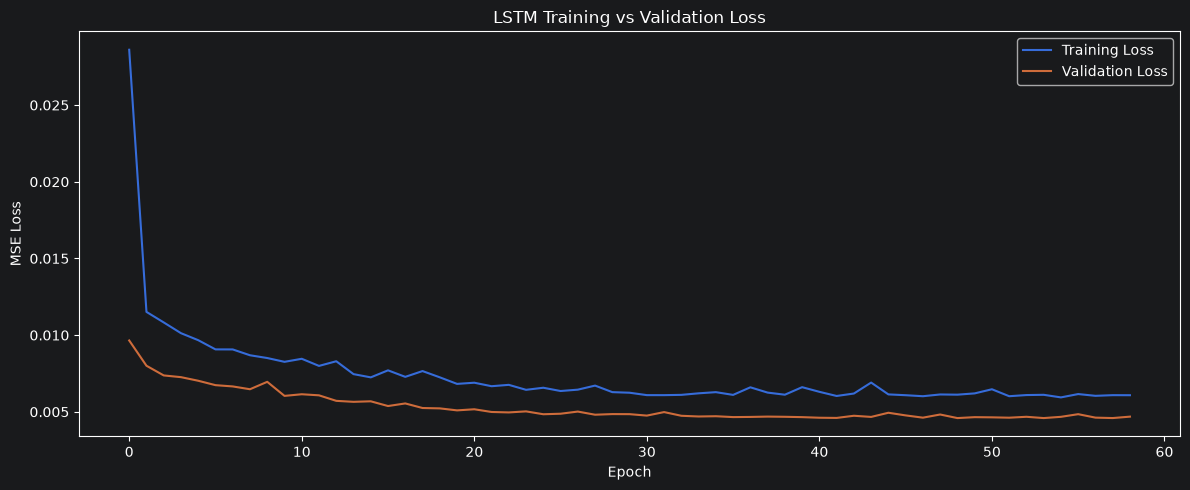

In [14]:
# ============================================
# 11. TRAINING HISTORY
# ============================================

plt.figure(figsize=(12, 5))

plt.plot(
    history.history["loss"],
    label="Training Loss"
)

plt.plot(
    history.history["val_loss"],
    label="Validation Loss"
)

plt.title("LSTM Training vs Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.legend()

plt.tight_layout()
plt.show()

In [15]:
# ============================================
# 12. LSTM VALIDATION FORECAST
# ============================================

validation_pred_scaled = lstm_model.predict(
    X_validation,
    verbose=0
)

# Convert predictions back to original AQI scale
validation_pred = scaler.inverse_transform(
    validation_pred_scaled
).flatten()

# Actual validation AQI
validation_actual = validation["AQI"].values

# Create a Series with correct dates
lstm_validation_forecast = pd.Series(
    validation_pred,
    index=validation.index,
    name="LSTM"
)

print(lstm_validation_forecast.head())
print()
print("Actual:")
print(validation["AQI"].head())

Date
2018-07-03    124.544868
2018-07-04    130.741394
2018-07-05    133.698868
2018-07-06    134.052856
2018-07-07    146.685669
Name: LSTM, dtype: float32

Actual:
Date
2018-07-03    122.0
2018-07-04    128.0
2018-07-05    130.0
2018-07-06    147.0
2018-07-07    155.0
Name: AQI, dtype: float64


In [20]:
# ============================================
# 13. LSTM VALIDATION METRICS
# ============================================

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error
)

def evaluate_forecast(actual, predicted):

    # Align actual and predicted
    actual = np.asarray(actual)
    predicted = np.asarray(predicted)

    # MAE
    mae = mean_absolute_error(
        actual,
        predicted
    )

    # RMSE
    rmse = np.sqrt(
        mean_squared_error(
            actual,
            predicted
        )
    )

    # MAPE
    # Avoid division by zero
    mask = actual != 0

    mape = np.mean(
        np.abs(
            (actual[mask] - predicted[mask])
            / actual[mask]
        )
    ) * 100

    return {
        "MAE": mae,
        "RMSE": rmse,
        "MAPE": mape
    }


lstm_validation_metrics = evaluate_forecast(
    validation["AQI"],
    lstm_validation_forecast
)

lstm_validation_metrics

{'MAE': 34.42642795092439,
 'RMSE': np.float64(46.55255171260815),
 'MAPE': np.float64(16.13256753830676)}

In [22]:
# ============================================
# 14. LSTM VALIDATION COMPARISON
# ============================================

# Previous validation results from Notebook 03
# Recreated here so Notebook 05 is self-contained.

validation_comparison = pd.DataFrame([
    {
        "Model": "Naive",
        "MAE": 135.084932,
        "RMSE": 173.624362,
        "MAPE": 46.632066
    },
    {
        "Model": "Seasonal Naive",
        "MAE": 66.387945,
        "RMSE": 88.689442,
        "MAPE": 32.316794
    },
    {
        "Model": "ARIMA(2,0,2)",
        "MAE": 90.394255,
        "RMSE": 105.990094,
        "MAPE": 50.647020
    },
    {
        "Model": "Random Forest",
        "MAE": 35.677709,
        "RMSE": 49.092308,
        "MAPE": 16.969363
    },
    {
        "Model": "XGBoost",
        "MAE": 36.844652,
        "RMSE": 50.267831,
        "MAPE": 17.729354
    },
    {
        "Model": "Linear Regression",
        "MAE": 34.092489,
        "RMSE": 46.872868,
        "MAPE": 15.966136
    },
    {
        "Model": "LSTM",
        "MAE": lstm_validation_metrics["MAE"],
        "RMSE": lstm_validation_metrics["RMSE"],
        "MAPE": lstm_validation_metrics["MAPE"]
    }
])

validation_comparison = validation_comparison.sort_values(
    "MAE"
).reset_index(drop=True)

validation_comparison

,Model,MAE,RMSE,MAPE
0,Linear Regression,34.092489,46.872868,15.966136
1,LSTM,34.426428,46.552552,16.132568
2,Random Forest,35.677709,49.092308,16.969363
3,XGBoost,36.844652,50.267831,17.729354
4,Seasonal Naive,66.387945,88.689442,32.316794
5,"ARIMA(2,0,2)",90.394255,105.990094,50.647020
6,Naive,135.084932,173.624362,46.632066


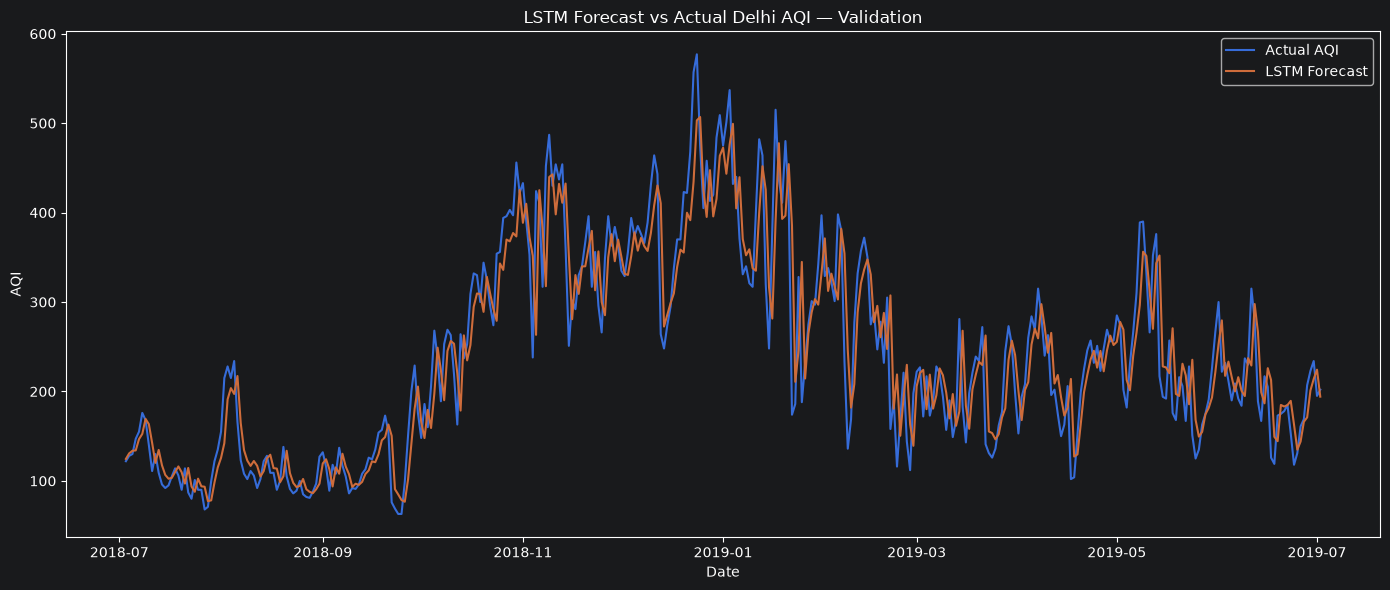

In [23]:
# ============================================
# 15. LSTM VALIDATION FORECAST
# ============================================

plt.figure(figsize=(14, 6))

plt.plot(
    validation.index,
    validation["AQI"],
    label="Actual AQI"
)

plt.plot(
    lstm_validation_forecast.index,
    lstm_validation_forecast,
    label="LSTM Forecast"
)

plt.title("LSTM Forecast vs Actual Delhi AQI — Validation")
plt.xlabel("Date")
plt.ylabel("AQI")
plt.legend()

plt.tight_layout()
plt.show()

In [24]:
# ============================================
# 16. BEST LSTM EPOCH
# ============================================

best_epoch = np.argmin(
    history.history["val_loss"]
) + 1

best_val_loss = min(
    history.history["val_loss"]
)

print("Best epoch:", best_epoch)
print("Best validation loss:", best_val_loss)

Best epoch: 49
Best validation loss: 0.004591699689626694


In [25]:
# ============================================
# 17. COMBINED TRAINING DATA
# ============================================

train_validation = pd.concat([
    train,
    validation
])

print("Combined training size:", len(train_validation))
print(
    "Start:",
    train_validation.index.min()
)
print(
    "End:",
    train_validation.index.max()
)

Combined training size: 1644
Start: 2015-01-01 00:00:00
End: 2019-07-02 00:00:00


In [26]:
# ============================================
# 18. FINAL SCALER
# ============================================

final_scaler = MinMaxScaler()

train_validation_scaled = final_scaler.fit_transform(
    train_validation[["AQI"]]
)

test_scaled_final = final_scaler.transform(
    test[["AQI"]]
)

print(
    "Combined scaled range:",
    train_validation_scaled.min(),
    train_validation_scaled.max()
)

Combined scaled range: 0.0 1.0


In [27]:
# ============================================
# 19. FINAL TRAINING SEQUENCES
# ============================================

X_final_train, y_final_train = create_sequences(
    train_validation_scaled,
    LOOKBACK
)

print("X_final_train:", X_final_train.shape)
print("y_final_train:", y_final_train.shape)

X_final_train: (1614, 30, 1)
y_final_train: (1614,)


In [28]:
# ============================================
# 20. FINAL LSTM MODEL
# ============================================

final_lstm_model = Sequential([

    LSTM(
        64,
        input_shape=(LOOKBACK, 1)
    ),

    Dropout(0.2),

    Dense(
        32,
        activation="relu"
    ),

    Dense(1)
])

final_lstm_model.compile(
    optimizer="adam",
    loss="mse"
)

final_lstm_model.summary()

/Users/gyanvi/PycharmProjects/AQI-Time-Series-Forecasting/.venv-tf/lib/python3.12/site-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm_1 (LSTM)                   │ (None, 64)             │        16,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 19,009 (74.25 KB)

 Trainable params: 19,009 (74.25 KB)

 Non-trainable params: 0 (0.00 B)

In [29]:
# ============================================
# 21. TRAIN FINAL LSTM
# ============================================

final_history = final_lstm_model.fit(
    X_final_train,
    y_final_train,
    epochs=best_epoch,
    batch_size=32,
    verbose=1
)

Epoch 1/49
51/51 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - loss: 0.0239
Epoch 2/49
51/51 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0106
Epoch 3/49
51/51 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0099
Epoch 4/49
51/51 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0094
Epoch 5/49
51/51 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0086
Epoch 6/49
51/51 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0083
Epoch 7/49
51/51 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0081
Epoch 8/49
51/51 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0077
Epoch 9/49
51/51 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0074
Epoch 10/49
51/51 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0071
Epoch 11/49
51/51 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0068
Epoch 12/49
51/51 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0068
Epoch 13/49
51/51 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0068
Epoch 14/49
51/51 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0066
Epoch 15/49
51/51 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0064
Epoch 16/49
51/51 ━

In [30]:
# ============================================
# 22. TEST SEQUENCES
# ============================================

test_input = np.concatenate([
    train_validation_scaled[-LOOKBACK:],
    test_scaled_final
])

X_test, y_test = create_sequences(
    test_input,
    LOOKBACK
)

print("X_test:", X_test.shape)
print("y_test:", y_test.shape)

X_test: (365, 30, 1)
y_test: (365,)


In [31]:
# ============================================
# 23. FINAL LSTM TEST FORECAST
# ============================================

test_pred_scaled = final_lstm_model.predict(
    X_test,
    verbose=0
)

test_pred = final_scaler.inverse_transform(
    test_pred_scaled
).flatten()

lstm_test_forecast = pd.Series(
    test_pred,
    index=test.index,
    name="LSTM"
)

print(lstm_test_forecast.head())
print()
print(lstm_test_forecast.tail())

Date
2019-07-03    216.066315
2019-07-04    182.515808
2019-07-05    144.950729
2019-07-06    147.271301
2019-07-07    133.425079
Name: LSTM, dtype: float32

Date
2020-06-27    122.227959
2020-06-28    127.776939
2020-06-29    195.803909
2020-06-30    223.847366
2020-07-01    128.352646
Name: LSTM, dtype: float32


In [32]:
# ============================================
# 24. FINAL LSTM TEST METRICS
# ============================================

lstm_test_metrics = evaluate_forecast(
    test["AQI"],
    lstm_test_forecast
)

print("Final LSTM Test Metrics:")
print(lstm_test_metrics)

Final LSTM Test Metrics:
{'MAE': 34.73215656019237, 'RMSE': np.float64(46.73743863672653), 'MAPE': np.float64(21.520906597745167)}


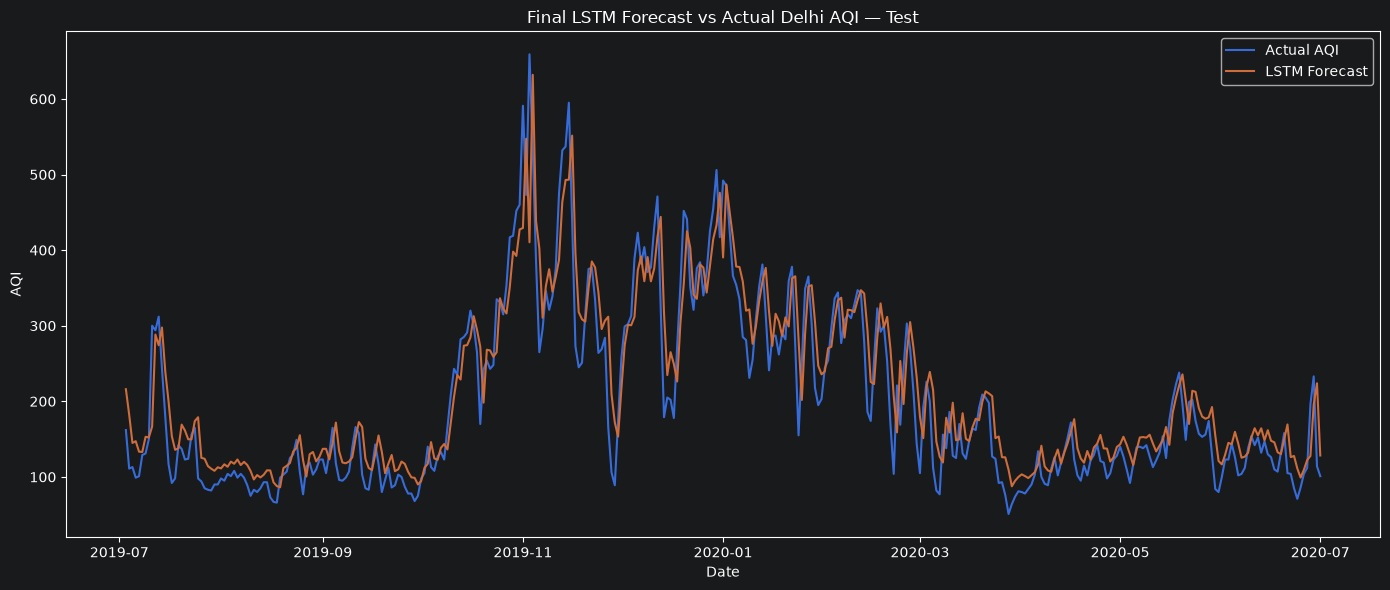

In [33]:
# ============================================
# 25. FINAL LSTM FORECAST
# ============================================

plt.figure(figsize=(14, 6))

plt.plot(
    test.index,
    test["AQI"],
    label="Actual AQI"
)

plt.plot(
    lstm_test_forecast.index,
    lstm_test_forecast,
    label="LSTM Forecast"
)

plt.title(
    "Final LSTM Forecast vs Actual Delhi AQI — Test"
)

plt.xlabel("Date")
plt.ylabel("AQI")
plt.legend()

plt.tight_layout()
plt.show()

In [34]:
# ============================================
# 26. FINAL TEST MODEL COMPARISON
# ============================================

final_test_results = pd.DataFrame([
    {
        "Model": "LSTM",
        "Category": "Deep Learning",
        "MAE": lstm_test_metrics["MAE"],
        "RMSE": lstm_test_metrics["RMSE"],
        "MAPE": lstm_test_metrics["MAPE"]
    },
    {
        "Model": "Fourier + ARIMA(2,0,2)",
        "Category": "Statistical",
        "MAE": 73.432871,
        "RMSE": 93.702537,
        "MAPE": 51.061704
    },
    {
        "Model": "Seasonal Naive",
        "Category": "Statistical Baseline",
        "MAE": 75.619178,
        "RMSE": 98.415822,
        "MAPE": 51.659498
    },
    {
        "Model": "Naive",
        "Category": "Statistical Baseline",
        "MAE": 99.013699,
        "RMSE": 118.178110,
        "MAPE": 62.695832
    },
    {
        "Model": "Random Forest",
        "Category": "Machine Learning",
        "MAE": 110.915634,
        "RMSE": 125.613686,
        "MAPE": 88.323993
    },
    {
        "Model": "ARIMA(2,0,2)",
        "Category": "Statistical",
        "MAE": 114.198056,
        "RMSE": 128.918109,
        "MAPE": 86.160062
    },
    {
        "Model": "SARIMA(1,0,1)(1,0,1,7)",
        "Category": "Statistical",
        "MAE": 173.668410,
        "RMSE": 215.356767,
        "MAPE": 80.460293
    }
])

final_test_results = final_test_results.sort_values(
    "MAE"
).reset_index(drop=True)

final_test_results

,Model,Category,MAE,RMSE,MAPE
0,LSTM,Deep Learning,34.732157,46.737439,21.520907
1,"Fourier + ARIMA(2,0,2)",Statistical,73.432871,93.702537,51.061704
2,Seasonal Naive,Statistical Baseline,75.619178,98.415822,51.659498
3,Naive,Statistical Baseline,99.013699,118.178110,62.695832
4,Random Forest,Machine Learning,110.915634,125.613686,88.323993
5,"ARIMA(2,0,2)",Statistical,114.198056,128.918109,86.160062
6,"SARIMA(1,0,1)(1,0,1,7)",Statistical,173.668410,215.356767,80.460293


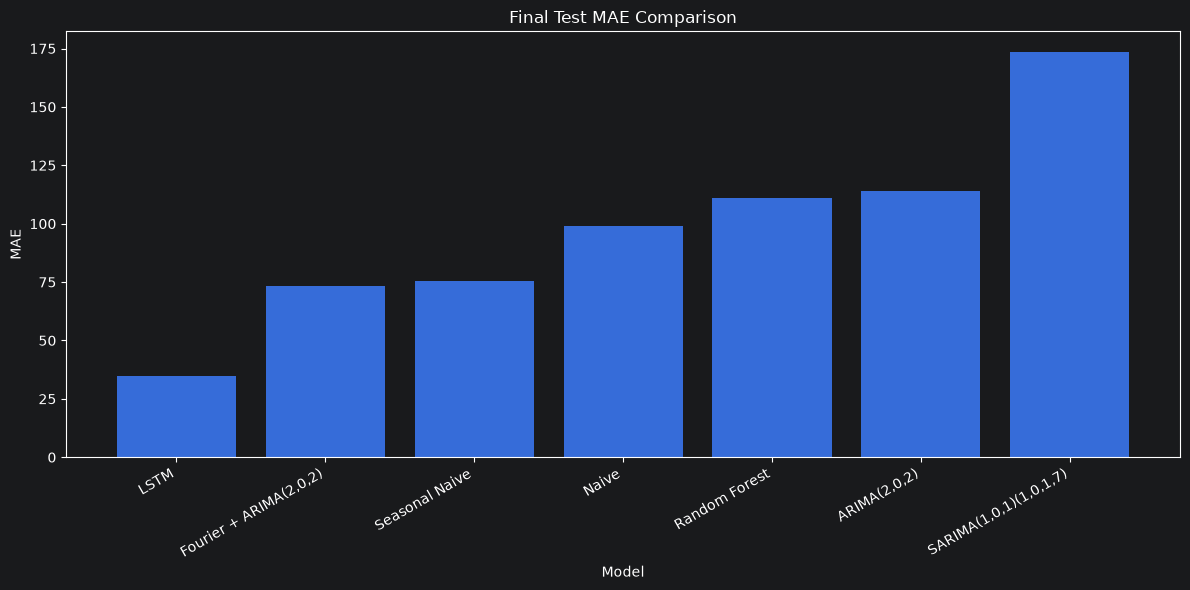

In [35]:
# ============================================
# 27. FINAL MAE COMPARISON
# ============================================

plt.figure(figsize=(12, 6))

plt.bar(
    final_test_results["Model"],
    final_test_results["MAE"]
)

plt.title("Final Test MAE Comparison")
plt.xlabel("Model")
plt.ylabel("MAE")

plt.xticks(
    rotation=30,
    ha="right"
)

plt.tight_layout()
plt.show()

In [36]:
# ============================================
# 28. LSTM IMPROVEMENT
# ============================================

best_statistical_mae = 73.432871

lstm_mae = lstm_test_metrics["MAE"]
lstm_rmse = lstm_test_metrics["RMSE"]
lstm_mape = lstm_test_metrics["MAPE"]

mae_improvement = (
    (best_statistical_mae - lstm_mae)
    / best_statistical_mae
) * 100

print(
    f"LSTM MAE improvement over Fourier + ARIMA: "
    f"{mae_improvement:.2f}%"
)

LSTM MAE improvement over Fourier + ARIMA: 52.70%


In [37]:
# ============================================
# 29. SAVE FINAL RESULTS
# ============================================

import os

os.makedirs("../outputs/forecasts", exist_ok=True)
os.makedirs("../outputs/figures", exist_ok=True)

final_test_results.to_csv(
    "../outputs/final_model_comparison.csv",
    index=False
)

lstm_test_forecast.to_csv(
    "../outputs/forecasts/final_lstm_forecast.csv",
    header=True
)

print("Final results saved successfully.")

Final results saved successfully.


In [38]:
# ============================================
# 30. SAVE FINAL LSTM MODEL
# ============================================

final_lstm_model.save(
    "../models/final_lstm_model.keras"
)

print("LSTM model saved successfully.")

LSTM model saved successfully.


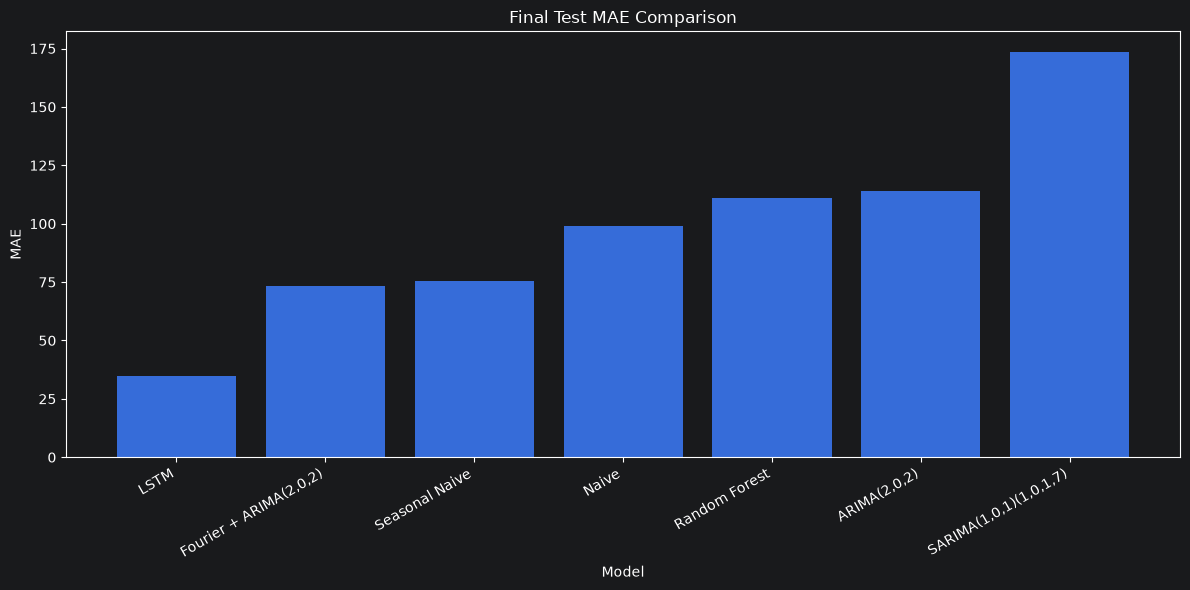

In [39]:
# ============================================
# 32. SAVE FINAL MODEL COMPARISON FIGURE
# ============================================

plt.figure(figsize=(12, 6))

plt.bar(
    final_test_results["Model"],
    final_test_results["MAE"]
)

plt.title("Final Test MAE Comparison")
plt.xlabel("Model")
plt.ylabel("MAE")

plt.xticks(
    rotation=30,
    ha="right"
)

plt.tight_layout()

plt.savefig(
    "../outputs/figures/final_model_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

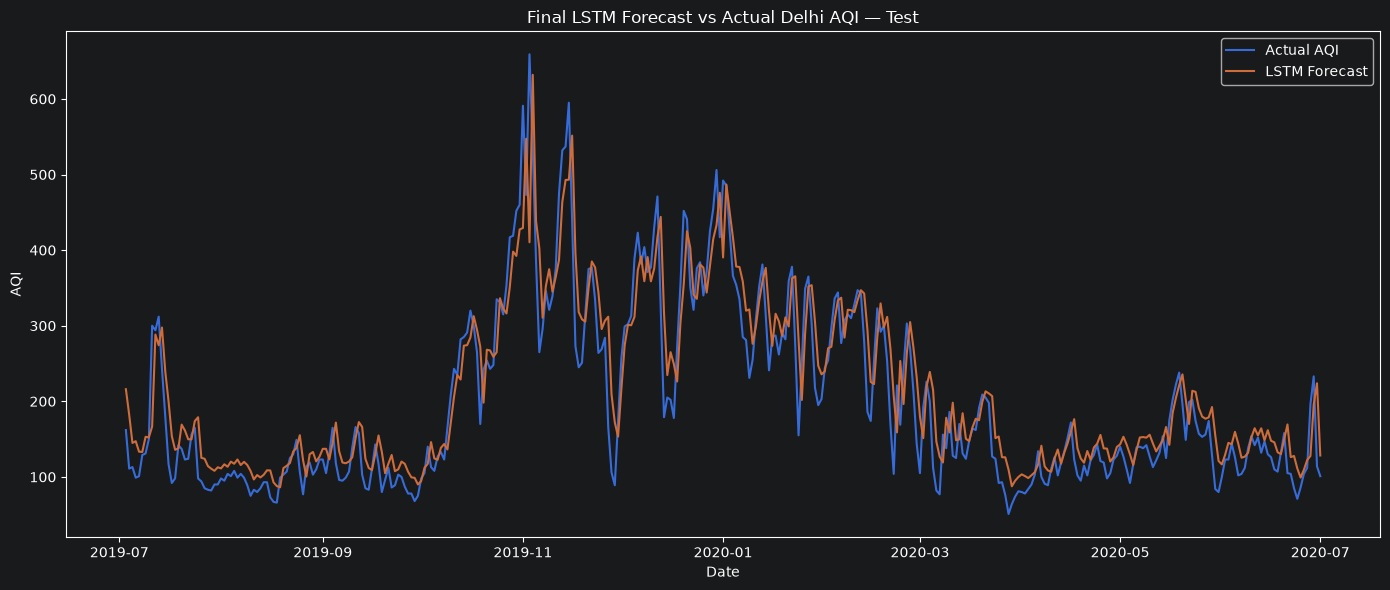

In [40]:
# ============================================
# 33. SAVE FINAL LSTM FORECAST FIGURE
# ============================================

plt.figure(figsize=(14, 6))

plt.plot(
    test.index,
    test["AQI"],
    label="Actual AQI"
)

plt.plot(
    lstm_test_forecast.index,
    lstm_test_forecast,
    label="LSTM Forecast"
)

plt.title(
    "Final LSTM Forecast vs Actual Delhi AQI — Test"
)

plt.xlabel("Date")
plt.ylabel("AQI")

plt.legend()

plt.tight_layout()

plt.savefig(
    "../outputs/figures/final_lstm_forecast.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

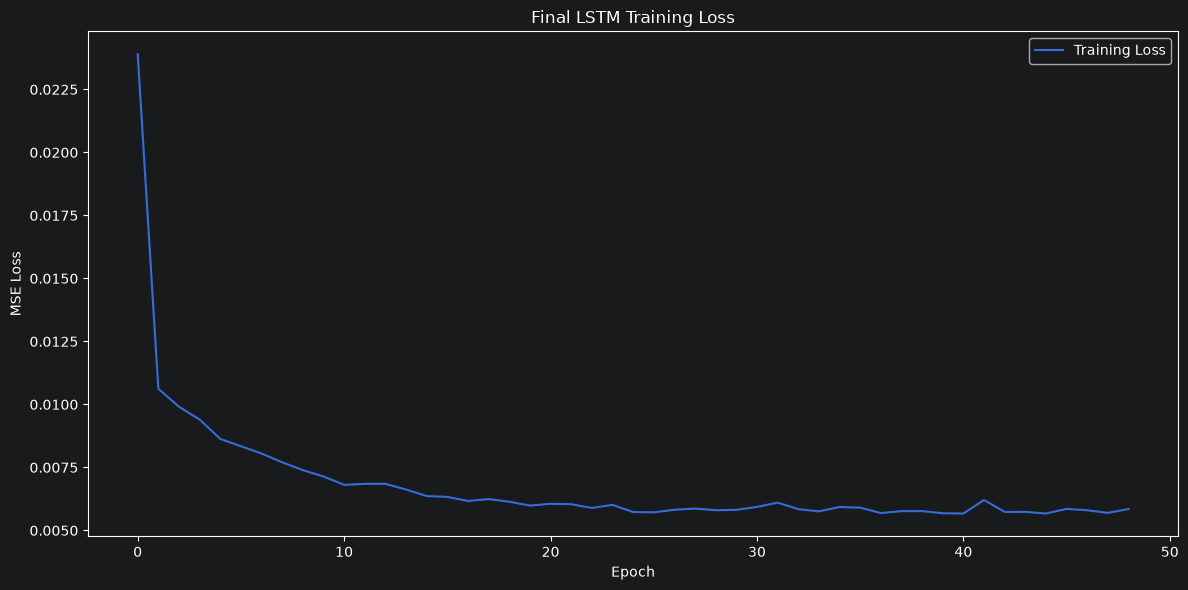

In [41]:
# ============================================
# 34. SAVE LSTM TRAINING CURVE
# ============================================

plt.figure(figsize=(12, 6))

plt.plot(
    final_history.history["loss"],
    label="Training Loss"
)

plt.title("Final LSTM Training Loss")

plt.xlabel("Epoch")
plt.ylabel("MSE Loss")

plt.legend()

plt.tight_layout()

plt.savefig(
    "../outputs/figures/lstm_training_loss.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [42]:
import joblib

joblib.dump(
    final_scaler,
    "../models/lstm_scaler.pkl"
)

print("Scaler saved successfully.")

Scaler saved successfully.


In [43]:
import os

print("Figures:")
for file in os.listdir("../outputs/figures"):
    print("  ", file)

print("\nForecasts:")
for file in os.listdir("../outputs/forecasts"):
    print("  ", file)

print("\nModels:")
for file in os.listdir("../models"):
    print("  ", file)

Figures:
   final_model_comparison.png
   final_lstm_forecast.png
   lstm_training_loss.png

Forecasts:
   final_seasonal_naive_forecast.csv
   final_random_forest_forecast.csv
   final_fourier_arima_forecast.csv
   final_lstm_forecast.csv

Models:
   lstm_scaler.pkl
   final_lstm_model.keras


In [44]:
print("FINAL TEST PERIOD")
print("Start:", test.index.min())
print("End:", test.index.max())
print("Observations:", len(test))

print("\nFINAL LSTM METRICS")
print("MAE :", round(lstm_test_metrics["MAE"], 2))
print("RMSE:", round(lstm_test_metrics["RMSE"], 2))
print("MAPE:", round(lstm_test_metrics["MAPE"], 2))

print("\nBEST MODEL:")
print(final_test_results.iloc[0])

FINAL TEST PERIOD
Start: 2019-07-03 00:00:00
End: 2020-07-01 00:00:00
Observations: 365

FINAL LSTM METRICS
MAE : 34.73
RMSE: 46.74
MAPE: 21.52

BEST MODEL:
Model                LSTM
Category    Deep Learning
MAE             34.732157
RMSE            46.737439
MAPE            21.520907
Name: 0, dtype: object
